# ПЗ-1. Vision Transformer изнутри

Цель: сравнить реализации PatchEmbed, оценить рост матрицы внимания и изучить головы DINO. Выполняйте ячейки последовательно в Google Colab.


In [6]:
%pip install -q transformers==4.46.3 huggingface_hub==0.26.2

In [7]:
import random, platform, importlib.metadata as md
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import pandas as pd, matplotlib.pyplot as plt
from torchvision.datasets import CIFAR10
from transformers import AutoImageProcessor, ViTModel
from huggingface_hub import model_info
random.seed(42); np.random.seed(42); torch.manual_seed(42)
print('Python',platform.python_version())
for p in ['torch','torchvision','transformers','huggingface_hub','matplotlib']: print(p,md.version(p))

Python 3.13.18
torch 2.14.1+cpu
torchvision 0.29.1+cpu
transformers 4.46.3
huggingface_hub 0.26.2
matplotlib 3.10.0


## 1. Эквивалентность двух реализаций

Свёртка и линейное преобразование выполняют одинаковое скалярное произведение для каждого патча.


In [8]:
class ExplicitPatchEmbed(nn.Module):
    def __init__(self,p,d):
        super().__init__(); self.p=p; self.proj=nn.Linear(3*p*p,d,bias=False)
    def forward(self,x): return self.proj(F.unfold(x,kernel_size=self.p,stride=self.p).transpose(1,2))
class ConvPatchEmbed(nn.Module):
    def __init__(self,p,d):
        super().__init__(); self.proj=nn.Conv2d(3,d,p,stride=p,bias=False)
    def forward(self,x): return self.proj(x).flatten(2).transpose(1,2)
p,d=16,64
a=ExplicitPatchEmbed(p,d); b=ConvPatchEmbed(p,d)
with torch.no_grad(): b.proj.weight.copy_(a.proj.weight.reshape(d,3,p,p))
x=torch.randn(2,3,224,224)
diff=(a(x)-b(x)).abs().max().item()
print('Максимальное расхождение:',diff)
assert diff<1e-5

Максимальное расхождение: 2.6226043701171875e-06


## 2. Число патчей и стоимость внимания

Для неполных краёв используется целочисленное деление без дополнения; CLS не учитывается. Рост сравнивается с 224×224 при том же P.


In [9]:
rows=[]
for p in (14,16):
    base=(224//p)**2
    for w,h in [(224,224),(336,336),(448,448),(896,672)]:
        N=(w//p)*(h//p)
        rows.append({'P':p,'Размер':f'{w}×{h}','N':N,'N²':N*N,'Рост N²':(N/base)**2,'Остатки':(w%p,h%p)})
display(pd.DataFrame(rows))

,P,Размер,N,N²,Рост N²,Остатки
0,14,224×224,256,65536,1.0000,"(0, 0)"
1,14,336×336,576,331776,5.0625,"(0, 0)"
2,14,448×448,1024,1048576,16.0000,"(0, 0)"
3,14,896×672,3072,9437184,144.0000,"(0, 0)"
4,16,224×224,196,38416,1.0000,"(0, 0)"
5,16,336×336,441,194481,5.0625,"(0, 0)"
6,16,448×448,784,614656,16.0000,"(0, 0)"
7,16,896×672,2352,5531904,144.0000,"(0, 0)"


## 3. Карты внимания CLS

Три изображения из тестовой части CIFAR-10, загружаемой с сайта Университета Торонто. Для каждой головы последнего слоя карта накладывается на изображение.


Модель: facebook/dino-vitb16 ревизия: f205d5d8e640a89a2b8ef0369670dfc37cc07fc2


100%|██████████| 170M/170M [14:44<00:00, 193kB/s] 


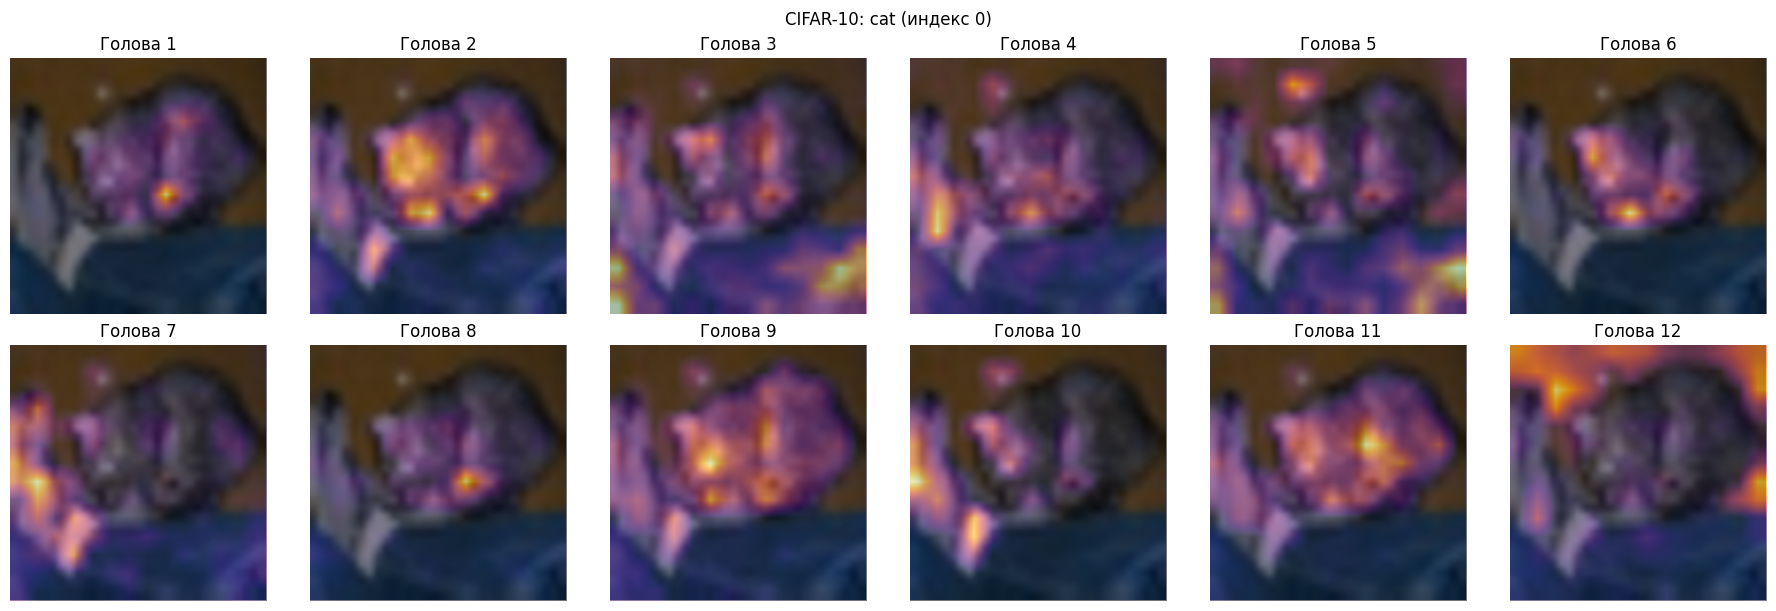

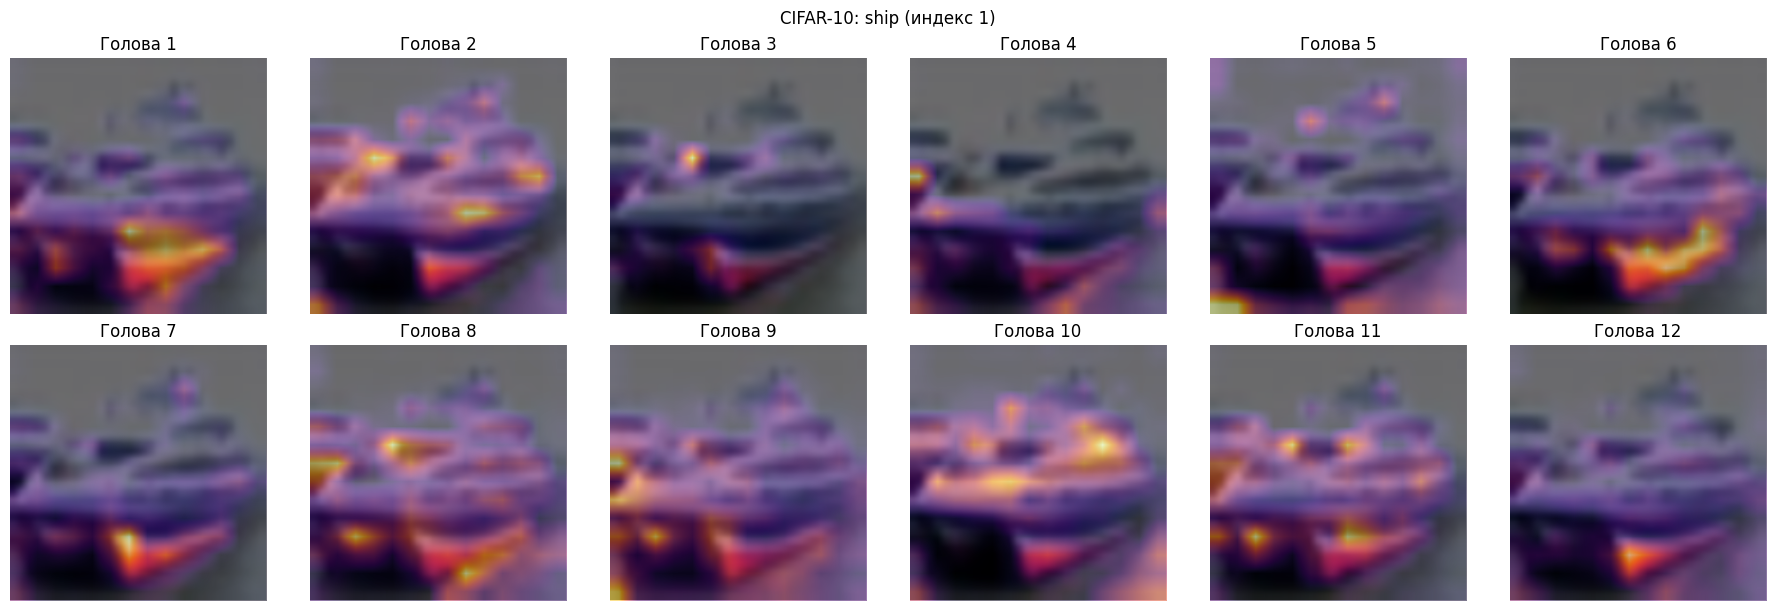

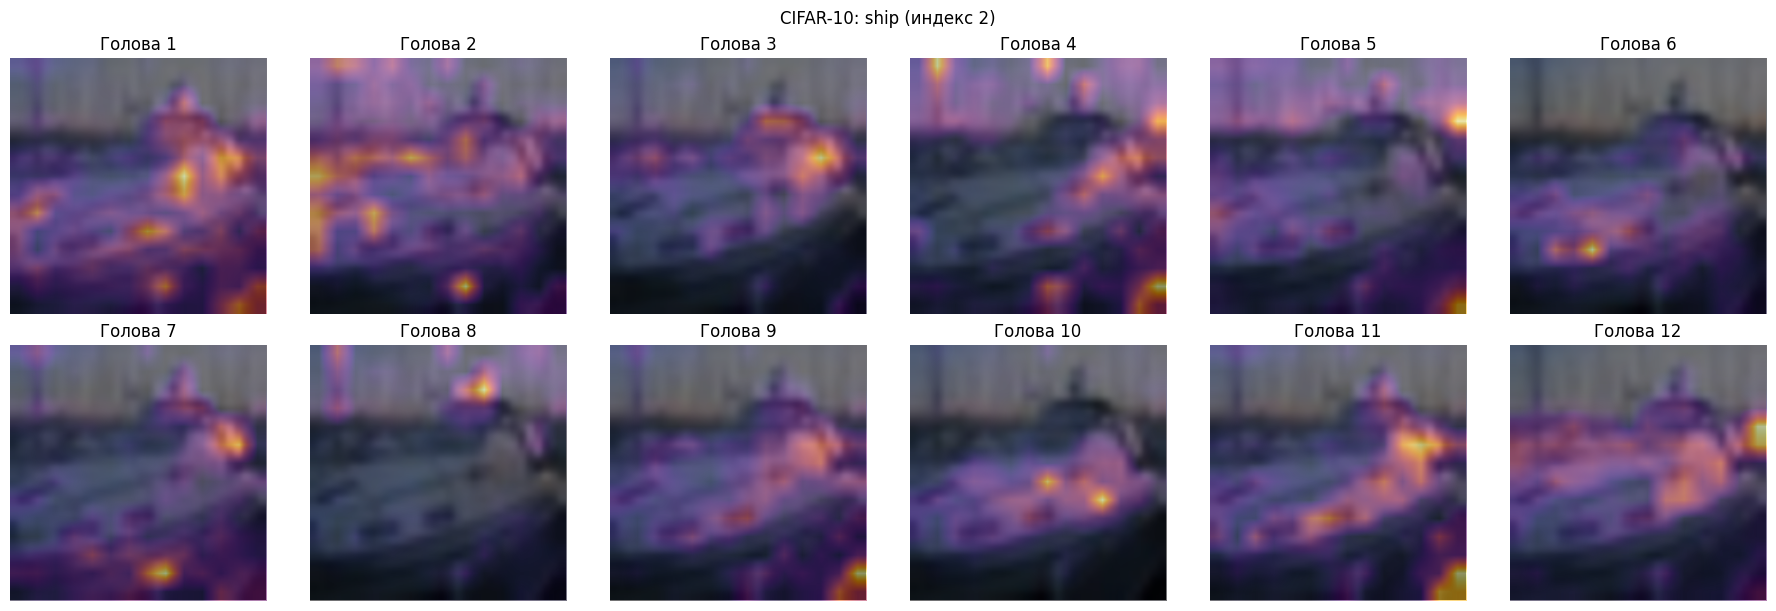

In [10]:
MODEL='facebook/dino-vitb16'
REV='f205d5d8e640a89a2b8ef0369670dfc37cc07fc2'
print('Модель:', MODEL, 'ревизия:', REV)
processor=AutoImageProcessor.from_pretrained(MODEL,revision=REV)
model=ViTModel.from_pretrained(MODEL,revision=REV,attn_implementation='eager',add_pooling_layer=False).eval()
device='cuda' if torch.cuda.is_available() else 'cpu'; model.to(device)
data=CIFAR10(root='./data',train=False,download=True)
for index in [0,1,2]:
    im,label=data[index]
    inputs=processor(images=im,return_tensors='pt').to(device)
    with torch.inference_mode(): out=model(**inputs,output_attentions=True)
    att=out.attentions[-1][0,:,0,1:].cpu().reshape(-1,14,14)
    fig,axes=plt.subplots(2,6,figsize=(18,6),constrained_layout=True)
    for i,ax in enumerate(axes.flat):
        ax.imshow(im.resize((224,224))); ax.imshow(att[i],extent=(0,224,224,0),cmap='inferno',alpha=.55,interpolation='bilinear'); ax.set_title(f'Голова {i+1}'); ax.axis('off')
    fig.suptitle(f'CIFAR-10: {data.classes[label]} (индекс {index})'); plt.show()


## 4. Интерпретация и контрольные вопросы

На изображении кошки головы 2, 6, 9 и 11 выделяют разные участки объекта; головы 4, 7 и 10 сильнее реагируют на область слева, а голова 12 — также на фон. На изображении корабля с индексом 1 головы 1, 6, 7 и 12 концентрируются около нижней части судна, тогда как голова 10 выделяет верхние элементы и палубу. На другом изображении корабля головы 3, 7 и 11 выделяют правую часть объекта, а головы 4 и 5 также обращают заметное внимание на фон и края.

Следовательно, головы распределяют внимание неодинаково: одни выделяют части объекта, другие — границы или контекст. Изображения CIFAR-10 имеют низкое разрешение, поэтому точное соответствие отдельных пятен деталям ограничено. Карта показывает распределение внимания CLS по патчам и сама по себе не доказывает причинный вклад пикселей в решение модели.

**Почему ViT без предобучения уступает CNN на малых выборках?** CNN закладывает локальность и разделение весов, а ViT должен выучить пространственные закономерности из данных. Предобучение компенсирует этот недостаток.

**Что меняется при перекрытии?** Шаг становится меньше размера ядра P. Патчи повторно используют часть пикселей, их число растёт; unfold и свёртка остаются эквивалентными при одинаковых ядре, шаге, дополнении и весах.
